# Regularization in Regression — Python companion
**Machine Learning for Biomedical Data (MLBD), Week 3**

This notebook follows the R lecture `lectures/week3/regularization.Rmd` section by section, replacing `glmnet` with scikit-learn's `Lasso`, `ElasticNet`, `LassoCV`, and `LogisticRegression`. It uses the same example datasets as the `glmnet` package.

## Bias-variance tradeoff and regularization
See the slides for the concepts. In short: penalizing (shrinking) coefficients adds a little bias but can greatly reduce variance and overfitting.

| | Penalty | Python |
|---|---|---|
| Ridge | L2: $\lambda\sum_j \beta_j^2$ | `Ridge` |
| Lasso | L1: $\lambda\sum_j \lvert\beta_j\rvert$ | `Lasso` |
| Elastic net | L1 + L2 | `ElasticNet` |


## glmnet ↔ scikit-learn: matching the parameters
`glmnet` minimizes
$$\frac{1}{2N}\sum_{i}(y_i-{\bf x}_i'\beta)^2 + \lambda\left[\alpha\|\beta\|_1 + \tfrac{1-\alpha}{2}\|\beta\|_2^2\right],$$
and scikit-learn's `ElasticNet` minimizes **exactly the same function**, with different names:

| glmnet | scikit-learn |
|---|---|
| `lambda` (penalty strength) | `alpha` |
| `alpha` (lasso/ridge mix; 1 = lasso) | `l1_ratio` |

⚠️ The names are swapped: glmnet's `alpha` is *not* scikit-learn's `alpha`.

One more difference: **glmnet standardizes the predictors** internally (then reports coefficients on the original scale); scikit-learn does not. So we standardize first and convert back. With that, the two give the same answers.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Data live in python/data/ in the course repo. If you're running this
# notebook somewhere else (e.g., Google Colab), it falls back to GitHub.
LOCAL = "../data/"
REMOTE = "https://raw.githubusercontent.com/wevanjohnson/2026_Fall_MLBD/main/python/data/"
DATA = LOCAL if os.path.exists(LOCAL) else REMOTE
from sklearn.linear_model import Lasso, LassoCV, LogisticRegression, lasso_path
from sklearn.model_selection import KFold, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

def to_original_scale(model, scaler):
    """Convert coefficients fit on standardized X back to the original scale (like glmnet)."""
    b = np.ravel(model.coef_) / scaler.scale_
    b0 = np.ravel(model.intercept_)[0] - np.sum(b * scaler.mean_)
    return b0, b

## Regression regularization: the glmnet quick start example

In [2]:
qs = pd.read_csv(DATA + "QuickStartExample.csv")
y = qs.pop("y").to_numpy()
x = qs.to_numpy()
names = qs.columns
x.shape

(100, 20)

The equivalent of `fit <- glmnet(x, y)`: the whole **lasso path** over a grid of λ values.

In [3]:
scaler = StandardScaler().fit(x)
xs = scaler.transform(x)

# glmnet's default lambda sequence: 100 values from lambda_max down to 1e-4 * lambda_max
lam_max = np.max(np.abs(xs.T @ (y - y.mean()))) / len(y)
lambdas = np.geomspace(lam_max, lam_max * 1e-4, 100)
lambdas, coefs_std, _ = lasso_path(xs, y - y.mean(), alphas=lambdas)
coefs = coefs_std / scaler.scale_[:, None]          # back to the original scale
coefs.shape                                          # (predictors, lambdas)

(20, 100)

Coefficient paths, like `plot(fit)`: each line is one predictor, plotted against the L1 norm of the coefficient vector.

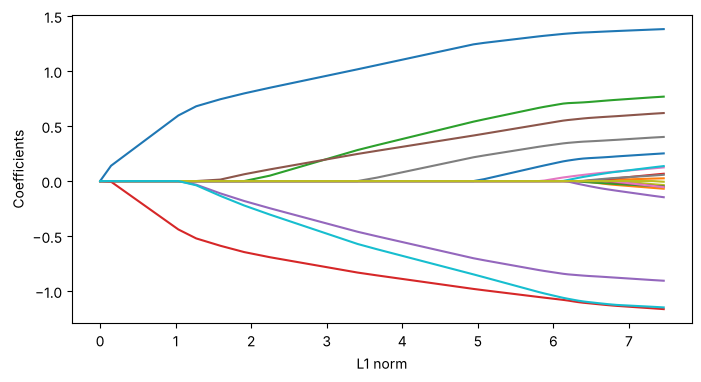

In [4]:
l1_norm = np.abs(coefs).sum(axis=0)
plt.figure(figsize=(8, 4))
for j in range(coefs.shape[0]):
    plt.plot(l1_norm, coefs[j])
plt.xlabel("L1 norm"); plt.ylabel("Coefficients")
plt.show()

A summary along the path, like `print(fit)`: number of nonzero coefficients (Df), % deviance explained, and λ.

In [5]:
def pct_dev(b):
    b0 = y.mean() - x.mean(axis=0) @ b
    rss = np.sum((y - b0 - x @ b) ** 2)
    return 100 * (1 - rss / np.sum((y - y.mean()) ** 2))

path = pd.DataFrame({"Df": (coefs != 0).sum(axis=0),
                     "%Dev": [round(pct_dev(coefs[:, k]), 2) for k in range(coefs.shape[1])],
                     "Lambda": lambdas.round(4)})
path.iloc[::8]

,Df,%Dev,Lambda
0,0,0.00,1.6308
8,5,51.54,0.7747
16,7,80.53,0.3681
24,8,88.21,0.1749
32,9,90.23,0.0831
40,16,90.93,0.0395
48,19,91.22,0.0187
56,19,91.30,0.0089
64,20,91.32,0.0042
72,20,91.32,0.0020


Coefficients at a single λ, like `coef(fit, s = 0.1)`. These match the glmnet vignette (to within glmnet's convergence tolerance).

In [6]:
m = Lasso(alpha=0.1).fit(xs, y)
b0, b = to_original_scale(m, scaler)
pd.Series(np.r_[b0, b], index=["(Intercept)"] + list(names)).round(4).replace(0, ".")

(Intercept)    0.1509
V1             1.3206
V2                  .
V3             0.6751
V4                  .
V5            -0.8174
V6             0.5214
V7             0.0048
V8             0.3194
V9                  .
V10                 .
V11            0.1425
V12                 .
V13                 .
V14             -1.06
V15                 .
V16                 .
V17                 .
V18                 .
V19                 .
V20           -1.0219
dtype: object

## Choosing λ by cross-validation
`cv.glmnet(x, y)` → `LassoCV`. We plot the CV mean squared error (± 1 SE) against log(λ), like `plot(cvfit)`.

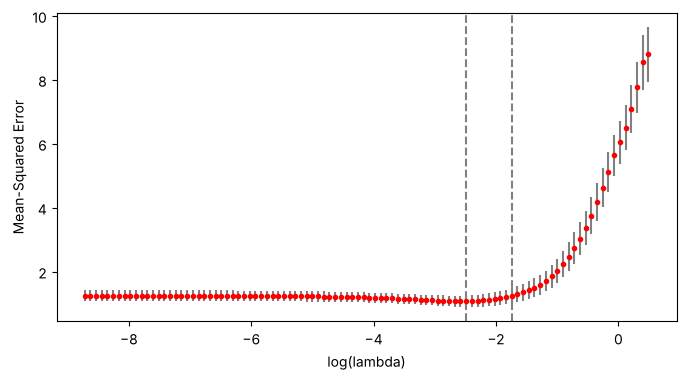

In [7]:
cvfit = make_pipeline(StandardScaler(),
                      LassoCV(alphas=lambdas, cv=KFold(10, shuffle=True, random_state=1)))
cvfit.fit(x, y)
lasso_cv = cvfit[-1]

mse = lasso_cv.mse_path_.mean(axis=1)
se = lasso_cv.mse_path_.std(axis=1) / np.sqrt(lasso_cv.mse_path_.shape[1])
lam_min = lasso_cv.alpha_
lam_1se = lasso_cv.alphas_[np.argmax(mse <= mse[np.argmin(mse)] + se[np.argmin(mse)])]

plt.figure(figsize=(8, 4))
plt.errorbar(np.log(lasso_cv.alphas_), mse, yerr=se, fmt="o", color="red", ecolor="gray", ms=3)
for lam in (lam_min, lam_1se):
    plt.axvline(np.log(lam), ls="--", color="gray")
plt.xlabel("log(lambda)"); plt.ylabel("Mean-Squared Error")
plt.show()

The two dashed lines: $\lambda_{min}$ (lowest CV error) and $\lambda_{1se}$ (largest λ within one SE of the minimum, a simpler model that is about as accurate).

$\lambda_{min}$ and its coefficients, like `coef(cvfit, s = "lambda.min")`:

In [8]:
print("lambda.min:", round(lam_min, 4), "| lambda.1se:", round(lam_1se, 4))
b0, b = to_original_scale(lasso_cv, cvfit[0])
pd.Series(np.r_[b0, b], index=["(Intercept)"] + list(names)).round(4).replace(0, ".")

lambda.min: 0.0831 | lambda.1se: 0.1749


(Intercept)    0.1494
V1             1.3298
V2                  .
V3              0.691
V4                  .
V5            -0.8312
V6             0.5367
V7             0.0201
V8             0.3319
V9                  .
V10                 .
V11            0.1624
V12                 .
V13                 .
V14           -1.0708
V15                 .
V16                 .
V17                 .
V18                 .
V19                 .
V20           -1.0434
dtype: object

> CV folds are random, so λ<sub>min</sub> will differ a little from the R slides (and from run to run in R, too).

## Example: logistic regression elastic net
For a binary response, glmnet minimizes $-\frac{1}{N}\,\text{log-likelihood} + \lambda \times \text{penalty}$.

scikit-learn's `LogisticRegression` instead minimizes $C \times (-\text{log-likelihood}) + \text{penalty}$, so **$C = 1/(N\lambda)$**. We use `solver="saga"`, which supports the L1 penalty.

Like the slides, we use an even lasso/ridge mix: glmnet's `alpha = 0.5` is scikit-learn's `l1_ratio = 0.5`.

In [9]:
bx = pd.read_csv(DATA + "BinomialExample.csv")
by = bx.pop("y").to_numpy()
bX = bx.to_numpy()
N = len(by)
bX.shape, np.bincount(by.astype(int))

((100, 30), array([44, 56]))

In [10]:
import sklearn
from packaging.version import Version

def enet_logistic(C, l1_ratio=0.5):
    """Elastic-net logistic regression (glmnet family = "binomial", alpha = l1_ratio)."""
    if Version(sklearn.__version__) >= Version("1.8"):
        return LogisticRegression(l1_ratio=l1_ratio, C=C, solver="saga", max_iter=20000)
    return LogisticRegression(penalty="elasticnet", l1_ratio=l1_ratio, C=C,
                              solver="saga", max_iter=20000)

10-fold CV using **misclassification error** (`type.measure = "class"`):

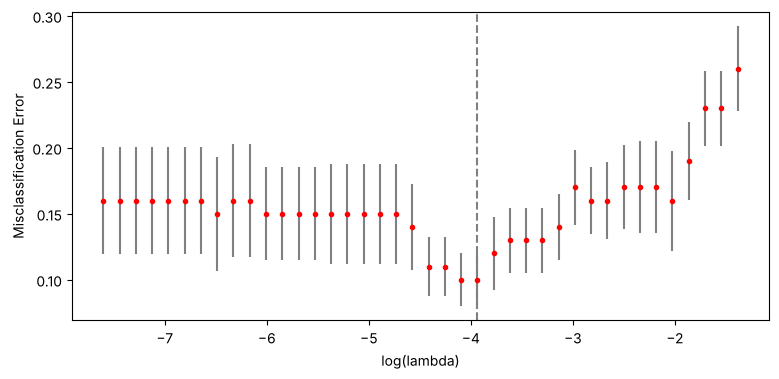

lambda.min: 0.0195


In [11]:
lam_grid = np.logspace(np.log10(0.25), np.log10(0.0005), 40)

search = GridSearchCV(
    make_pipeline(StandardScaler(), enet_logistic(C=1.0)),
    param_grid={"logisticregression__C": 1 / (N * lam_grid)},
    cv=StratifiedKFold(10, shuffle=True, random_state=1),
    scoring="accuracy")
search.fit(bX, by)

err = 1 - search.cv_results_["mean_test_score"]
err_se = search.cv_results_["std_test_score"] / np.sqrt(10)
best_lam = 1 / (N * search.best_params_["logisticregression__C"])

plt.figure(figsize=(9, 4))
plt.errorbar(np.log(lam_grid), err, yerr=err_se, fmt="o", color="red", ecolor="gray", ms=3)
plt.axvline(np.log(best_lam), ls="--", color="gray")
plt.xlabel("log(lambda)"); plt.ylabel("Misclassification Error")
plt.show()
print("lambda.min:", round(best_lam, 4))

Coefficients at $\lambda_{min}$ (on the original scale). Some are exactly zero: the L1 part of the elastic net selects variables.

In [12]:
best = search.best_estimator_
b0, b = to_original_scale(best[-1], best[0])
coef = pd.Series(np.r_[b0, b], index=["(Intercept)"] + list(bx.columns)).round(4)
print("nonzero coefficients:", int((coef.iloc[1:] != 0).sum()), "of", len(coef) - 1)
coef.replace(0, ".")

nonzero coefficients: 26 of 30


(Intercept)    0.2171
V1             0.0903
V2             0.5861
V3            -0.4467
V4            -1.0053
V5            -0.2577
V6            -0.8295
V7                  .
V8            -0.5508
V9              0.663
V10           -1.2774
V11           -0.1308
V12            -0.115
V13           -0.0384
V14            0.0025
V15                 .
V16            0.3775
V17           -0.0436
V18           -0.0951
V19                 .
V20            -0.114
V21                 .
V22            0.2213
V23            0.3967
V24            -0.079
V25            0.6176
V26           -0.3751
V27           -0.1539
V28            0.2888
V29           -0.2454
V30            0.1373
dtype: object

## Application: NHANES
The CDC's National Health and Nutrition Examination Survey, via the R `NHANES` package (2009-2012). `nhanes_adults.csv` has adults with complete data on 17 predictors; we predict **diabetes**.

In [13]:
nh = pd.read_csv(DATA + "nhanes_adults.csv")
y_nh = (nh.pop("Diabetes") == "Yes").astype(int).to_numpy()

# Dummy-code factors like R's model.matrix (first level is the reference)
levels = {"Gender": ["female", "male"],
          "Race1": ["Black", "Hispanic", "Mexican", "White", "Other"],
          "Education": ["8th Grade", "9 - 11th Grade", "High School", "Some College", "College Grad"],
          "PhysActive": ["No", "Yes"], "Smoke100": ["No", "Yes"],
          "HealthGen": ["Excellent", "Vgood", "Good", "Fair", "Poor"]}
for col, lv in levels.items():
    nh[col] = pd.Categorical(nh[col], categories=lv)
X_nh = pd.get_dummies(nh, drop_first=True).astype(float)
print(X_nh.shape, "| diabetes:", y_nh.sum())

(3570, 26) | diabetes: 419


Train/test split (70/30), then ridge, elastic net, and lasso tuned by 10-fold CV on AUC with the one-standard-error rule, plus plain (unpenalized) logistic regression. We use the same λ grid trick as above, $C = 1/(N\lambda)$.

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

Xtr, Xte, ytr, yte = train_test_split(X_nh, y_nh, test_size=0.3, random_state=2026, stratify=y_nh)
Ntr = len(ytr)
lam_grid = np.logspace(np.log10(0.1), np.log10(0.0002), 30)

def fit_1se(l1_ratio):
    if l1_ratio == 0:      # ridge
        est = LogisticRegression(C=1.0, max_iter=5000)
    else:
        est = enet_logistic(C=1.0, l1_ratio=l1_ratio)
    gs = GridSearchCV(make_pipeline(StandardScaler(), est),
                      {"logisticregression__C": 1 / (Ntr * lam_grid)},
                      cv=StratifiedKFold(10, shuffle=True, random_state=1), scoring="roc_auc")
    gs.fit(Xtr, ytr)
    mean = gs.cv_results_["mean_test_score"]; se = gs.cv_results_["std_test_score"] / np.sqrt(10)
    best = np.argmax(mean)
    i1se = np.argmax(mean >= mean[best] - se[best])     # grid runs from large to small lambda
    model = make_pipeline(StandardScaler(), est.set_params(C=1 / (Ntr * lam_grid[i1se]))).fit(Xtr, ytr)
    return model

results = {}
for name, r in [("ridge", 0), ("enet", 0.5), ("lasso", 1.0)]:
    mdl = fit_1se(r)
    results[name] = [roc_auc_score(yte, mdl.predict_proba(Xte)[:, 1]),
                     int((np.abs(mdl[-1].coef_) > 1e-8).sum())]
glm = LogisticRegression(C=np.inf if Version(sklearn.__version__) >= Version("1.8") else 1e12,
                         max_iter=10000).fit(StandardScaler().fit_transform(Xtr), ytr)
sc_ = StandardScaler().fit(Xtr)
results["glm"] = [roc_auc_score(yte, glm.predict_proba(sc_.transform(Xte))[:, 1]), Xtr.shape[1]]
pd.DataFrame(results, index=["test AUC", "predictors"]).round(3)

,ridge,enet,lasso,glm
test AUC,0.833,0.83,0.833,0.842
predictors,26.000,9.00,10.000,26.000


Which variables does the lasso keep? (Standardized coefficients, so they're comparable.)

In [15]:
lasso_nh = fit_1se(1.0)
coef_nh = pd.Series(lasso_nh[-1].coef_[0], index=X_nh.columns)
coef_nh[coef_nh.abs() > 1e-8].round(3)

Age                0.723
BMI                0.323
Pulse              0.012
BPSysAve           0.094
TotChol           -0.091
DirectChol        -0.117
Race1_White       -0.096
HealthGen_Vgood   -0.161
HealthGen_Fair     0.101
HealthGen_Poor     0.158
dtype: float64

## NHANES: a small study
Repeat with only 150 training people, 20 times. Elastic net (λ<sub>min</sub>, 5-fold CV) vs. plain logistic regression:

In [16]:
import warnings
rng = np.random.default_rng(1)
out = []
for rep in range(20):
    idx = rng.choice(Ntr, 150, replace=False)
    xs_, ys_ = Xtr.iloc[idx], ytr[idx]
    gs = GridSearchCV(make_pipeline(StandardScaler(), enet_logistic(C=1.0)),
                      {"logisticregression__C": 1 / (150 * lam_grid)},
                      cv=StratifiedKFold(5, shuffle=True, random_state=rep), scoring="neg_log_loss")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        gs.fit(xs_, ys_)
        g = LogisticRegression(C=1e12, max_iter=10000)
        s_ = StandardScaler().fit(xs_)
        g.fit(s_.transform(xs_), ys_)
    out.append([roc_auc_score(yte, gs.predict_proba(Xte)[:, 1]),
                roc_auc_score(yte, g.predict_proba(s_.transform(Xte))[:, 1])])
pd.DataFrame(out, columns=["enet", "glm"]).mean().round(3)

enet    0.757
glm     0.678
dtype: float64

Same lessons as the slides: with plenty of data, regularization gives similar accuracy with fewer predictors; with a small study, it protects against overfitting. (Numbers differ a little from R because the splits and CV folds differ.)

## Session info

In [17]:
import sys, matplotlib
print("Python", sys.version.split()[0])
print("numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__)

Python 3.13.18
numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1 | matplotlib 3.11.2
